In [62]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import pandas as pd

from astropy.visualization import make_lupton_rgb
from random import random


In [63]:
fig_folder = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/Paper/Figures/'
col_fig = {'red': '#D55740', 'blue': '#6CB9D2', 'green': '#479E88', 'darkblue': '#415384', 'pink': '#E79F84'} #Dictionary with colors for the figures

#Setting for AAS Journals:
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial'],
    'font.size': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 11,
})

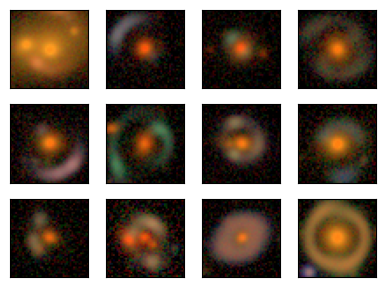

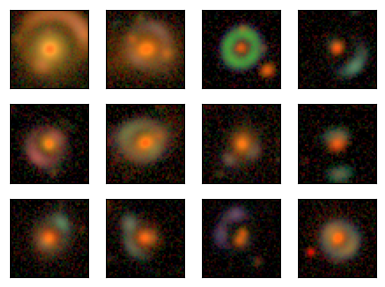

In [64]:
# Figure with collage of simulations (coming from segmentation folder)

path_sim = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/Segmentation/simulations/data/'
filename = 'simulation_file_500.fits'

with fits.open(path_sim + filename) as hdul:
    #print(hdul.info())
    images_sim = hdul[1].data
    data_sim = pd.DataFrame(hdul[4].data) 

#4x3
def collage_simulations(images, num, nrows=4, ncols=3):
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(4, 3))
    for i in range(nrows):
        for j in range(ncols):
            index = i * ncols + j
            if index < len(images):
                rgb = make_lupton_rgb(images[index][2], images[index][1], images[index][0],
                                      Q=9, stretch=40, minimum=(0, 0, 0))
                axes[i, j].imshow(rgb, aspect='equal')
                axes[i, j].set_xticks([])
                axes[i, j].set_yticks([])
    plt.tight_layout()
    namefig = fig_folder + 'collage_simulations{}.pdf'.format(num)
    #plt.savefig(namefig, dpi=300)
    plt.show()
    plt.close()

N = 2
for i in range(N):
    idx = np.random.choice(len(images_sim), size=12, replace=False)
    images_tmp = images_sim[idx]
    collage_simulations(images_tmp, num=i, nrows=3, ncols=4)


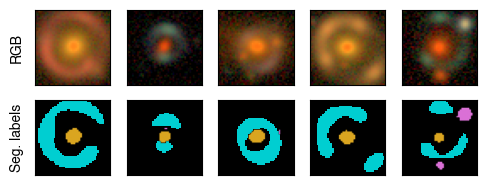

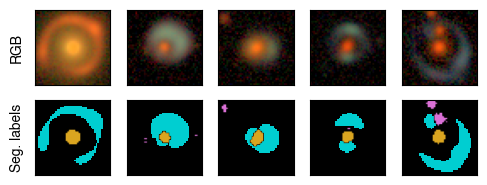

In [65]:
# Figure with collage of simulations and their segmentation labels

from matplotlib.colors import ListedColormap

path_sim = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/Segmentation/simulations/'
filename = 'labeled_simulations.fits'

with fits.open(path_sim + filename) as hdul:
    #print(hdul.info())
    images_sim = hdul[1].data
    seg_labels = hdul[4].data 

def collage_seglabels(images, seg_labels, num,nrows=2, ncols=2):
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5, 2))
    for j in range(ncols):
        index = j
        if index < len(images):
            rgb = make_lupton_rgb(images[index][2], images[index][1], images[index][0], Q=9, stretch=40, minimum=(0, 0, 0))
            rgb = np.flipud(rgb)
            axes[0, j].imshow(rgb, aspect='equal')
            axes[0, j].set_xticks([])
            axes[0, j].set_yticks([])

            thresh=0.
            source = np.ma.masked_less_equal(seg_labels[index][0], thresh)
            lens   = np.ma.masked_less_equal(seg_labels[index][1], thresh)
            noise  = np.ma.masked_less_equal(seg_labels[index][2], thresh)

            axes[1, j].set_facecolor('black')
            axes[1, j].imshow(source, cmap=ListedColormap(['darkturquoise']), interpolation='nearest',  origin='lower')
            axes[1, j].imshow(lens,   cmap=ListedColormap(['goldenrod']),     interpolation='bilinear', origin='lower')
            axes[1, j].imshow(noise,  cmap=ListedColormap(['orchid']),        interpolation='bilinear', origin='lower')
            axes[1, j].set_xticks([])
            axes[1, j].set_yticks([])
            
    axes[0, 0].set_ylabel("RGB", fontsize=10, labelpad=8)
    axes[1, 0].set_ylabel("Seg. labels", fontsize=10, labelpad=8)
    plt.tight_layout()
    namefig = fig_folder + 'collage_seglabels{}.pdf'.format(num)
    #plt.savefig(namefig, dpi=300)
    plt.show()
    plt.close()

N = 2
for i in range(N):
    idx = np.random.choice(len(images_sim), size=12, replace=False)
    images_tmp = images_sim[idx]
    seg_labels_tmp = seg_labels[idx]
    collage_seglabels(images_tmp, seg_labels_tmp, num=i, nrows=2, ncols=5)

18 0.9150616660383012


/var/folders/kn/2ng47p4x5qq6hwt5vqw16gfh0000gn/T/ipykernel_64976/1825249670.py:33: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  ax[0].plot(x, loss_train, 'o-', color=col_fig['darkblue'],markersize=4, linewidth=1., marker = "^", label='Training')
/var/folders/kn/2ng47p4x5qq6hwt5vqw16gfh0000gn/T/ipykernel_64976/1825249670.py:34: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  ax[0].plot(x, loss_valid, 'o-', color=col_fig['red'],markersize=4, linewidth=1., marker="P",label='Validation')
/var/folders/kn/2ng47p4x5qq6hwt5vqw16gfh0000gn/T/ipykernel_64976/1825249670.py:40: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  ax[1].plot(x, train_acc, 'o-', colo

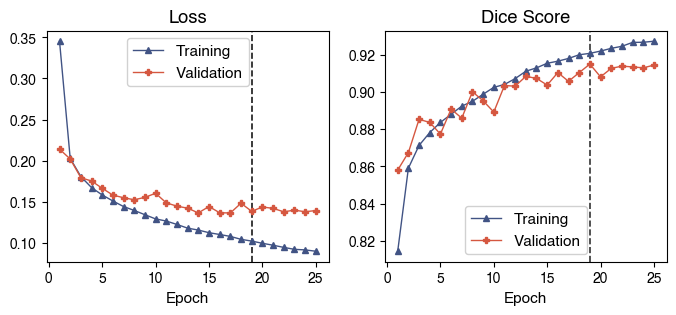

In [ ]:
# Figure with learning curve for the segmentation model (training and validation loss)

exp = 6
path_tmp = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/Segmentation/ML/Exp/model_exp' + str(exp) + '/'
filename = 'performance_data.csv'

data = pd.read_csv(path_tmp + filename)
data.head()

def plot_complete_performance(perf_data, epoch_stop):
    """
    Plot loss and accuracy vs. epoch | For all the training, and shows where it stopped training (saved model)
    Args:
        * model: trained model
    """
    epoch_stop = perf_data['validation_acc'].idxmax() #epoch -1
    val_lim = perf_data['validation_acc'][epoch_stop]
    print(epoch_stop, val_lim)

    loss_train = perf_data['loss_train']
    loss_valid = perf_data['loss_valid']
    train_acc = perf_data['train_acc']
    valid_acc = perf_data['validation_acc']


    
    x = np.linspace(1, len(perf_data), len(perf_data))
    fig, ax = plt.subplots(figsize=(8, 3), ncols=2)

    ax[0].set_title('Loss')
    ax[0].set_xlabel('Epoch')
    ax[0].axvline(epoch_stop+1, color='black', linestyle='--', linewidth=1.2, alpha=0.9)
    ax[0].plot(x, loss_train, 'o-', color=col_fig['darkblue'],markersize=4, linewidth=1., marker = "^", label='Training')  
    ax[0].plot(x, loss_valid, 'o-', color=col_fig['red'],markersize=4, linewidth=1., marker="P",label='Validation')  
    ax[0].legend(framealpha=0.9)
    
    ax[1].set_title('Dice Score')
    ax[1].set_xlabel('Epoch')
    ax[1].axvline(epoch_stop+1, color='black', linestyle='--', linewidth=1.2, alpha=0.8)
    ax[1].plot(x, train_acc, 'o-', color=col_fig['darkblue'],markersize=4, linewidth=1., marker = "^",label='Training')  
    ax[1].plot(x, valid_acc, 'o-', color=col_fig['red'],markersize=4, linewidth=1., marker="P", label='Validation')  

    ax[1].legend(loc='lower center', framealpha=0.9)
    
    #plt.savefig(fig_folder + 'Learning_curve_seg.pdf', bbox_inches='tight', dpi=300)
    plt.show()
    plt.close()

plot_complete_performance(data, epoch_stop=19)

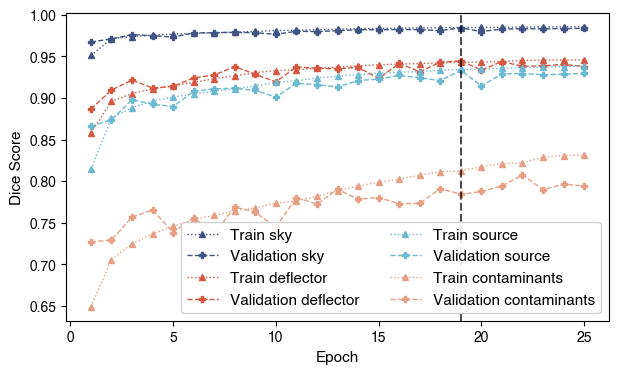

In [ ]:
# Figure with dice score for each class (source, lens, noise, sky) for the segmentation model

exp = 6
path_tmp = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/Segmentation/ML/Exp/model_exp' + str(exp) + '/'
filename = 'performance_data.csv'

data = pd.read_csv(path_tmp + filename)
data.head()


def plot_accs_perclass(perf_data):
    epoch_stop = perf_data['validation_acc'].idxmax() + 1
    
    x = np.linspace(1, len(perf_data), len(perf_data))
    
    plt.figure(figsize=(7, 4))
    plt.xlabel('Epoch')
    plt.ylabel('Dice Score')

    plt.plot(x, perf_data['train_acc_class3'], ':', color=col_fig['darkblue'],markersize=4, linewidth=1., marker = "^", label='Train sky') 
    plt.plot(x, perf_data['valid_acc_class3'], '--', color=col_fig['darkblue'],markersize=4, linewidth=1., marker = "P", label='Validation sky') 
    plt.plot(x, perf_data['train_acc_class1'], ':', color=col_fig['red'],markersize=4, linewidth=1., marker = "^", label='Train deflector') 
    plt.plot(x, perf_data['valid_acc_class1'], '--', color=col_fig['red'],markersize=4, linewidth=1., marker = "P", label='Validation deflector') 
    plt.plot(x, perf_data['train_acc_class0'], ':', color=col_fig['blue'],markersize=4, linewidth=1., marker = "^", label='Train source') 
    plt.plot(x, perf_data['valid_acc_class0'], '--', color=col_fig['blue'],markersize=4, linewidth=1., marker = "P", label='Validation source') 
    plt.plot(x, perf_data['train_acc_class2'], ':', color=col_fig['pink'],markersize=4, linewidth=1., marker = "^", label='Train contaminants') 
    plt.plot(x, perf_data['valid_acc_class2'], '--', color=col_fig['pink'],markersize=4, linewidth=1., marker = "P", label='Validation contaminants') 
    
    plt.axvline(epoch_stop, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
    plt.legend(ncols=2, loc='lower right', framealpha=0.9)
    #plt.savefig(fig_folder + 'Dice_perclass.pdf', bbox_inches='tight', dpi=300)
    plt.show(block=True)
    plt.close()


plot_accs_perclass(data)